# MX E2M3 + E2M1 / A32: volledige honderd-epochtraining

Een gezamenlijk model met FP32-updatemasters, twee BN-banken en distillatie.
Beide MX-modi worden direct afgerond; nog geen truncatie. Deze notebook leest
alleen opgeslagen JSON/CSV: geen training, downloads of modelupdates.

De oorspronkelijke vijfmodustraining gebruikte andere activatieprecisies en
meer passes. Een vergelijking daarmee is geen zuivere alleen-MX-ablatietest.
Beste en laatste checkpoint worden apart gerapporteerd; de testscore is niet
onafhankelijk van de beste-checkpointselectie. Een run is nog geen herhaling over seeds.


In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_weights_dual_reference100\\20261019_192538_709626_joint_run')


In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def load(name):
    with (RUN_DIR / name).open(encoding='utf-8') as handle:
        return json.load(handle)

report = load('run_report.json')
history = load('history.json')
metrics = pd.read_csv(RUN_DIR / 'epoch_metrics.csv')
selected = pd.read_csv(RUN_DIR / 'selected_metrics.csv')
times = pd.read_csv(RUN_DIR / 'epoch_times.csv')
selection = load('checkpoint_selection.json')
summary = load('training_summary.json')
estimate = load('timing_estimate.json')
synthetic = bool(report.get('synthetic_fixture_only', False))
if synthetic:
    display(Markdown('**SYNTHETISCHE SOFTWARETEST: geen SVHN-resultaten of bruikbare GPU-tijdschatting.**'))
assert report['schema'] == 'mx-weights-dual-reference100-report-v1'
display(pd.DataFrame([{'status': report['status'], 'epochs': summary['completed_epochs'],
                      'optimizerstappen': summary['optimizer_steps'],
                      'train_forwardpasses': summary['training_forward_passes'],
                      'volledige_training': summary['full_training_completed'], 'synthetisch': synthetic}]))


,status,epochs,optimizerstappen,train_forwardpasses,volledige_training,synthetisch
0,PASS,100,57300,114600,True,False


## Protocol en gegevenscontroles

In [3]:
c = report['config']
display(pd.DataFrame([{'model': c['model'], 'expand': c['expand'],
    'train': c['train_examples'], 'test': c['test_examples'], 'extra': c['extra_used'],
    'activatiebits': c['activation_bits'], 'master': c['master_dtype'],
    'blokgrootte': c['mx_block_size'], 'schaal': c['mx_scale_format'],
    'distillatie': c['distillation'], 'truncatie': c['truncation']}]))
assert set(metrics.weight_bits) == {4, 6}
assert (metrics.activation_bits == 32).all()
assert len(metrics) == 4 * summary['completed_epochs']
assert not metrics.duplicated(['epoch', 'phase', 'weight_bits']).any()
assert (metrics.top1_percent - 100 * metrics.correct1 / metrics.n).abs().max() < 1e-4
assert c['distillation'] and not c['truncation'] and not c['extra_used']
assert all(r['batchnorm_counters_correct'] for r in history['epochs'])
assert all(r['gradient_checks']['finite_gradient_checks'] ==
           r['gradient_checks']['detached_teacher_checks'] ==
           r['gradient_checks']['optimizer_steps_in_phase'] for r in history['epochs'])
assert all(r['test_optimizer_steps'] == 0 for r in history['epochs'])
print('Rapportcontroles: geslaagd. Geen onafhankelijke herevaluatie van checkpoints.')
if report.get('warnings'):
    display(pd.DataFrame(report['warnings'])[['category', 'message']].drop_duplicates())
else:
    print('Geen waarschuwingen geregistreerd.')

assert summary == load('completion_summary.json')
assert summary['full_training_completed'] == (summary['completed_epochs'] == 100)
assert report['full_training_completed'] == summary['full_training_completed']
assert c['target_final_epoch'] == c['planned_epochs'] == 100
assert summary['optimizer_steps'] == summary['completed_epochs'] * ((c['train_examples'] + c['batch_size'] - 1) // c['batch_size'])
assert summary['training_forward_passes'] == 2 * summary['optimizer_steps']
if summary['full_training_completed']:
    assert summary['last_epoch'] == 100 and len(metrics) == 400
else:
    display(Markdown('**ONDERBROKEN RUN: geen volledig honderd-epochresultaat.**'))


,model,expand,train,test,extra,activatiebits,master,blokgrootte,schaal,distillatie,truncatie
0,svhnq,2,73257,26032,False,32,float32,32,E8M0,True,False


Rapportcontroles: geslaagd. Geen onafhankelijke herevaluatie van checkpoints.


,category,message
0,DeprecationWarning,The argument 'device' of Tensor.pin_memory() i...
1,DeprecationWarning,The argument 'device' of Tensor.is_pinned() is...


## Nauwkeurigheid en checkpointkeuze
Beste betekent het eerste strikte maximum van **E2M3/A32** op de testset.
Beide modi komen uit datzelfde checkpoint. De testscore is niet onafhankelijk
van die selectie. Laatste wordt apart bewaard, ook als beide rollen gelijk zijn.

,weight_format,MXFP4_E2M1,MXFP6_E2M3
role,epoch,,
best_E2M3_test,75,94.9255,95.156
last_epoch,100,95.0254,95.033


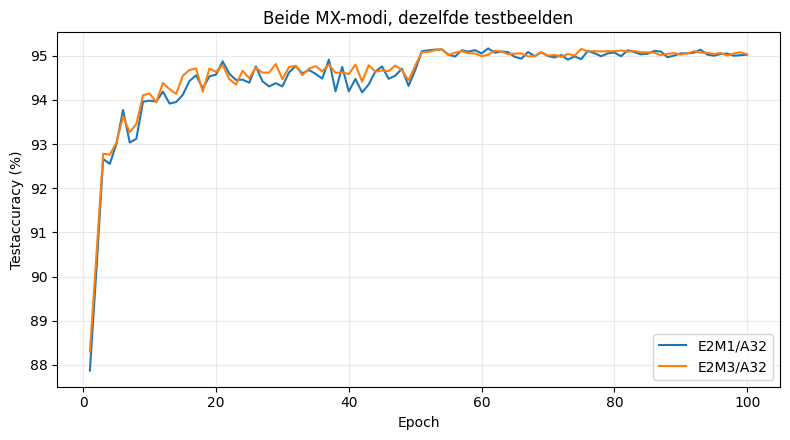

In [4]:
table = selected.pivot(index=['role', 'epoch'], columns='weight_format', values='count_top1_percent')
display(table.round(4))
test = metrics[metrics.phase == 'test'].copy()
high = test[test.weight_bits == 6].sort_values('epoch')
recomputed_best = int(high.loc[high.top1_percent.idxmax(), 'epoch'])
assert recomputed_best == selection['best']['epoch']
assert selected.groupby('role').epoch.nunique().eq(1).all()
fig, ax = plt.subplots(figsize=(8, 4.5))
for bit, group in test.groupby('weight_bits', sort=False):
    ax.plot(group.epoch, group.count_top1_percent, label=f'E2M{3 if bit == 6 else 1}/A32')
ax.set(xlabel='Epoch', ylabel='Testaccuracy (%)', title='Beide MX-modi, dezelfde testbeelden')
ax.legend(); ax.grid(True, alpha=.25); fig.tight_layout(); plt.show()


## Losses
Trainingsloss E2M3 = hard-label cross-entropy; trainingsloss E2M1 = soft-target cross-entropy.
Deze hebben niet hetzelfde leerdoel en zijn niet rechtstreeks als even grote fout
te vergelijken. **Testloss is voor beide modi hard-label cross-entropy.**

,epoch,phase,weight_format,objective_type,objective_loss
0,1,train,MXFP4_E2M1,recursive_soft_cross_entropy,0.785474
1,1,train,MXFP6_E2M3,hard_cross_entropy,0.669792
2,1,test,MXFP4_E2M1,hard_cross_entropy,0.391985
3,1,test,MXFP6_E2M3,hard_cross_entropy,0.378396
16,5,train,MXFP4_E2M1,recursive_soft_cross_entropy,0.293302
17,5,train,MXFP6_E2M3,hard_cross_entropy,0.245545
18,5,test,MXFP4_E2M1,hard_cross_entropy,0.242475
19,5,test,MXFP6_E2M3,hard_cross_entropy,0.238594
196,50,train,MXFP4_E2M1,recursive_soft_cross_entropy,0.140940
197,50,train,MXFP6_E2M3,hard_cross_entropy,0.081426


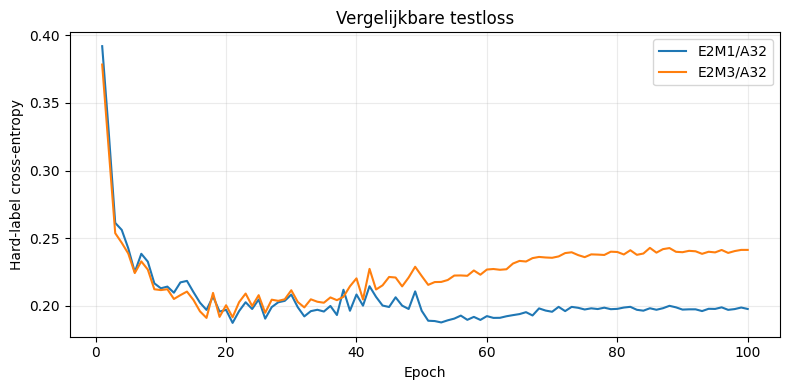

In [5]:
display(metrics[metrics.epoch.isin([1,5,50,51,75,76,90,91,100])][['epoch','phase','weight_format','objective_type','objective_loss']].round(6))
fig, ax = plt.subplots(figsize=(8, 4))
for bit, group in test.groupby('weight_bits', sort=False):
    ax.plot(group.epoch, group.objective_loss, label=f'E2M{3 if bit == 6 else 1}/A32')
ax.set(xlabel='Epoch', ylabel='Hard-label cross-entropy', title='Vergelijkbare testloss')
ax.legend(); ax.grid(True, alpha=.25); fig.tight_layout(); plt.show()


## Werkelijk gemeten tijd en updates
De voltooide epochtijd is een meting. Een extrapolatie bij een onderbroken run
is iets anders. Tijd betreft de geinstrumenteerde emulator, niet native MX-hardware.


,onderdeel,minuten
0,training,58.659
1,evaluatie,17.779
2,checkpoints,0.067
3,overige epochcontroles,0.176
4,totale gemeten epochtijd,76.680
5,huidige sessie inclusief voorbereiding/export,76.814


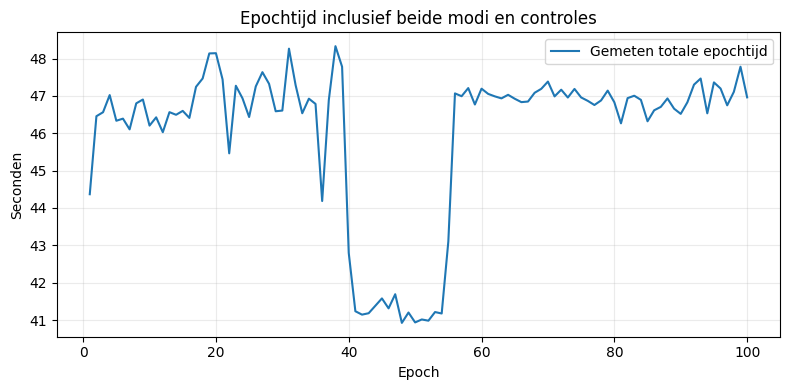

master_changed_values  \
epoch weight_bits                          
96    4                           125446   
      6                           125446   
97    4                           125448   
      6                           125448   
98    4                           125509   
      6                           125509   
99    4                           125446   
      6                           125446   
100   4                           125436   
      6                           125436   

                   changed_element_codes_including_padding  \
epoch weight_bits                                            
96    4                                                112   
      6                                                189   
97    4                                                116   
      6                                                192   
98    4                                                162   
      6                                                232   
99    4                                                174   
      6                                                247   
100   4                                                180   
      6                                                249   

                   changed_scale_codes  
epoch weight_bits                       
96    4                              0  
      6                              0  
97    4                              0  
      6                              0  
98    4                              1  
      6                              1  
99    4                              1  
      6                              1  
100   4                              1  
      6                              1

Masterupdates betreffen dezelfde gedeelde tensors; tel de modustotalen NIET bij elkaar op.
Initialisatiehash: a8fcd20c40a204ba24cabfa36258f9501d55b9d4d4bdfb8ba742b8c827af127f


In [6]:
timing_rows = [
    {'onderdeel': 'training', 'minuten': times.train_seconds.sum()/60},
    {'onderdeel': 'evaluatie', 'minuten': times.test_seconds.sum()/60},
    {'onderdeel': 'checkpoints', 'minuten': times.checkpoint_seconds.sum()/60},
    {'onderdeel': 'overige epochcontroles', 'minuten': times.other_seconds.sum()/60},
    {'onderdeel': 'totale gemeten epochtijd', 'minuten': times.total_epoch_seconds.sum()/60},
]
if report.get('session_wall_seconds') is not None:
    timing_rows.append({'onderdeel': 'huidige sessie inclusief voorbereiding/export',
                       'minuten': report['session_wall_seconds']/60})
display(pd.DataFrame(timing_rows).round(3))
if report.get('resumed_from'):
    print('Hervatte run: sessieduur is alleen dit proces; epochtijd bevat de eerdere epochs.')
if not summary['full_training_completed'] and estimate.get('available'):
    print(f"Voorlopige extrapolatie 100 epochs: {estimate['estimated_100_epoch_seconds']/60:.1f} minuten")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(times.epoch, times.total_epoch_seconds, label='Gemeten totale epochtijd')
ax.set(xlabel='Epoch', ylabel='Seconden', title='Epochtijd inclusief beide modi en controles')
ax.grid(True, alpha=.25); ax.legend(); fig.tight_layout(); plt.show()
updates = pd.read_csv(RUN_DIR / 'weight_updates.csv')
update_summary = updates.groupby(['epoch','weight_bits'])[
    ['master_changed_values','changed_element_codes_including_padding','changed_scale_codes']].sum()
display(update_summary.tail(10))
print('Masterupdates betreffen dezelfde gedeelde tensors; tel de modustotalen NIET bij elkaar op.')
print('Initialisatiehash:', summary['initial_model_sha256'])


## Learning rate: gebruikt tijdens de epoch versus klaargezet voor de volgende
De dalingen gebeuren na epochs 50, 75 en 90.


,epoch,lr_gebruikt,lr_volgende
0,1,0.001000,0.001000
4,5,0.001000,0.001000
49,50,0.001000,0.000100
50,51,0.000100,0.000100
74,75,0.000100,0.000010
75,76,0.000010,0.000010
89,90,0.000010,0.000001
90,91,0.000001,0.000001
99,100,0.000001,0.000001


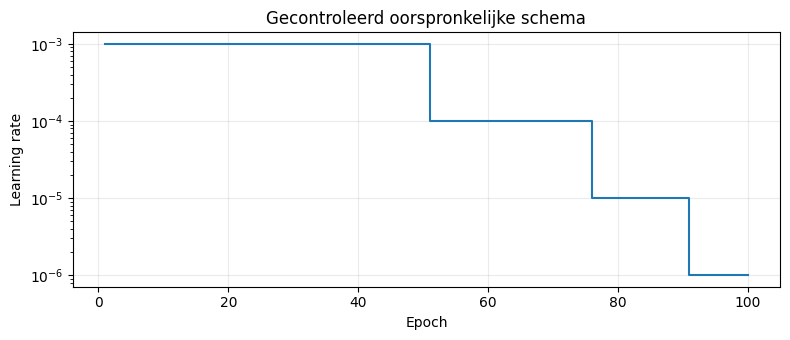

In [7]:
lr_rows=[]
for rec in history['epochs']:
    expected_used=expected_next=c['lr']
    for milestone in c['scheduler_milestones']:
        if milestone < rec['epoch']: expected_used *= c['scheduler_gamma']
        if milestone <= rec['epoch']: expected_next *= c['scheduler_gamma']
    assert rec['lr_used'] == expected_used and rec['lr_next'] == expected_next
    lr_rows.append({'epoch':rec['epoch'], 'lr_gebruikt':rec['lr_used'], 'lr_volgende':rec['lr_next']})
lr_table=pd.DataFrame(lr_rows)
display(lr_table[lr_table.epoch.isin([1,5,50,51,75,76,90,91,100])])
fig, ax = plt.subplots(figsize=(8,3.5))
ax.step(lr_table.epoch, lr_table.lr_gebruikt, where='post')
ax.set(xlabel='Epoch', ylabel='Learning rate', yscale='log', title='Gecontroleerd oorspronkelijke schema')
ax.grid(True, alpha=.25); fig.tight_layout(); plt.show()


## Exports en interpretatie
Per geselecteerd checkpoint worden **twee aparte direct afgeronde MX-exports** gemaakt.
E2M1 komt nog niet uit getrunceerde E2M3-codes. Dit is dus nog geen bewijs dat een opgeslagen
hoogste MX-model volstaat voor beide precisies. De exportcontrole vergelijkt gereconstrueerde
gewichten; deze trainingsrunner doet geen extra volledige testpass vanuit de exports.

In [8]:
export_rows=[]
for role, modes in report['mx_exports'].items():
    for bit, details in modes.items():
        export_rows.append({'role': role, 'bits': bit, 'epoch': details['epoch'],
                           'bestand_bytes': details['bytes'], 'gewichten_exact': details['decoded_weights_exact'],
                           'zonder_6_masters': details['six_fp32_masters_absent'],
                           'test_opnieuw': details['full_test_forward_rerun']})
display(pd.DataFrame(export_rows))
print('Deel feedback_bundle.zip uit:', RUN_DIR)


,role,bits,epoch,bestand_bytes,gewichten_exact,zonder_6_masters,test_opnieuw
0,best_E2M3_test,6,75,163813,True,True,False
1,best_E2M3_test,4,75,131173,True,True,False
2,last_epoch,6,100,163813,True,True,False
3,last_epoch,4,100,131173,True,True,False


Deel feedback_bundle.zip uit: C:\Users\renzo\master-thesis-mx\mx_runs\mx_weights_dual_reference100\20261019_192538_709626_joint_run
